# CONCH primary 04 — Within-TUM tissue/stain proximity: retained localized finding

This notebook reconstructs what the original investigation downloaded, processed, measured and concluded. It includes discarded/nonprimary screens and the agent's original determination. It does not impose a new acceptance rule or perform new confirmation.

**Evidence:** the original June 3 native sessions, ten source scripts recovered from successful original patches, and original per-image score tables (7,180 discovery; 1,800 confirmation; separate 4,000 expansion).

**Execution modes:** set `RUN_ORIGINAL_WORKFLOW=True` in the first code cell (or use the shared runner's `--original-workflow`) to acquire pinned raw inputs, run the original scoring scripts, and feed newly generated results into every curve below. The default is an explicitly labelled historical replay. The full route resumes verified stages in `generated/original-workflow`; a missing prerequisite or failed model stage stops execution. See `../WORKFLOW.md` for environment setup. No model run or large target download was performed while wiring this route.

**Reference evidence:** the 1,800-row reference matrix is now reconstructed from the exact unchanged public shard revision and original deterministic sampling/feature code. The exact reconstructed matrix, per-image identities, download receipts and pinned environment recipe are included; raw image archives are reacquired only in full-workflow mode. Every original axis level and both fitted baseline predictions reproduce. Small float32 kNN distance differences are recorded. Target predictions are selected by the execution mode above. The original saved reference CSV itself was not found: the original export omitted it, and a September chat already recorded the source folder missing.

**Original determination:** The original agent retained a localized TUM tissue-fraction finding after the original 1,800-image NONORM confirmation, then the separately archived 4,000-image expansion. The original language and both panels remain separate below.


## Run settings and prerequisites

Install Python 3.11 notebook requirements and the separate model environment using `../WORKFLOW.md`. Set the single switch below to execute the full workflow. It downloads seven pinned target-image shards and the 802 MB checkpoint, then scores 12,980 images. CUDA is the default; set the CPU flag only when intended. Model access must already be accepted on Hugging Face. Original batch size is 128. All six notebooks share one resumable run directory.

In [1]:
from pathlib import Path
import os, sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'original_pipeline.py').is_file())
# True downloads the pinned inputs and executes the original 12,980-image
# CONCH workflow. False is the explicitly labelled historical replay.
RUN_ORIGINAL_WORKFLOW = os.environ.get('SPECTRA_RUN_ORIGINAL_WORKFLOW','0') == '1'
if RUN_ORIGINAL_WORKFLOW and sys.version_info[:2] != (3,11):
    raise RuntimeError('Use the documented Python 3.11 notebook environment for the original workflow; compiled numerical packages must match the model interpreter ABI.')
INFERENCE_PYTHON = Path(os.environ.get('CONCH_INFERENCE_PYTHON', str(ROOT/'.venv-inference/bin/python')))
RUN_DIRECTORY = Path(os.environ.get('CONCH_RUN_DIRECTORY', str(ROOT/'generated/original-workflow')))
ALLOW_CPU_INFERENCE = False  # CUDA was used originally; CPU requires this deliberate opt-in.
print('Selected mode:', 'ORIGINAL WORKFLOW — image acquisition and new scoring' if RUN_ORIGINAL_WORKFLOW else 'HISTORICAL REPLAY — retained target scores')


Selected mode: HISTORICAL REPLAY — retained target scores


## 1. Exact inputs and original acquisition

In [2]:
from pathlib import Path
import os, sys, subprocess, tempfile, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'reconstruct_reference.py').is_file())
sys.path.insert(0,str(ROOT))
from bootstrap_replay import materialize
replay_payload=materialize()
print(f'Verified and materialized {len(replay_payload)} bundled replay tables/manifests; no image download.')
# Isolated, pinned numerical libraries: no changes to the notebook environment.
reference_site=Path(tempfile.gettempdir())/f'conch-reference-numeric-20261108-py{sys.version_info.major}{sys.version_info.minor}'
# A prior recovery cache is reusable only after real compiled imports succeed
# in this interpreter. New caches are specific to the interpreter ABI.
legacy_site=Path(tempfile.gettempdir())/'conch-reference-numeric-20261108'
if not reference_site.exists() and (legacy_site/'sklearn').is_dir():
    probe=subprocess.run([sys.executable,'-c',
        "import numpy,scipy,sklearn,pandas,pyarrow,PIL;assert numpy.__version__=='2.4.6';assert sklearn.__version__=='1.7.2'"],
        env=dict(os.environ,PYTHONPATH=str(legacy_site)),capture_output=True)
    if probe.returncode==0: reference_site=legacy_site
if not (reference_site/'sklearn').is_dir():
    import importlib.metadata, importlib.util
    expected={'numpy':'2.4.6','scipy':'1.16.2','scikit-learn':'1.7.2','pandas':'3.0.3','Pillow':'12.1.1','pyarrow':'17.0.0','requests':'2.32.3'}
    if all(importlib.metadata.version(k)==v for k,v in expected.items()):
        reference_site=Path(importlib.util.find_spec('numpy').origin).parent.parent
if not (reference_site/'sklearn').is_dir():
    subprocess.run([sys.executable,'-m','pip','install','--target',str(reference_site),
                    '-r',str(ROOT/'requirements_reference.txt')],check=True)
reference_env=dict(os.environ,PYTHONPATH=str(reference_site))
reference_path=ROOT/'data/nct_reference_features.reconstructed.csv'
image_archives=list((ROOT/'data/reference_reconstruction').glob('*_images.zip'))
assert reference_path.exists(), 'Portable reference payload did not materialize.'
# Full-mode acquisition and pixel reconstruction run inside original_pipeline.py.
# Historical replay only needs the exact reconstructed matrix, bundled above.
print('Reference acquisition: exact public revision 97765ecb14bf11ce7bb8779a1097d187844a67cb; first 200 matching-label images per original shard.')
print('Recipe: reconstruct_reference.py; numerical environment: requirements_reference.txt.')


Verified and materialized 5 bundled replay tables/manifests; no image download.


Reference acquisition: exact public revision 97765ecb14bf11ce7bb8779a1097d187844a67cb; first 200 matching-label images per original shard.
Recipe: reconstruct_reference.py; numerical environment: requirements_reference.txt.


In [3]:
sys.path.insert(0,str(ROOT))
from original_pipeline import verified_results
if RUN_ORIGINAL_WORKFLOW:
    command=[sys.executable,str(ROOT/'original_pipeline.py'),'--run',
             '--run-dir',str(RUN_DIRECTORY),'--inference-python',str(INFERENCE_PYTHON),
             '--numeric-site',str(reference_site)]
    if ALLOW_CPU_INFERENCE: command.append('--allow-cpu')
    # A failed prerequisite or stage raises here. There is no saved-score fallback.
    subprocess.run(command,check=True)
    RESULT_PATHS=verified_results(RUN_DIRECTORY)
    RUN=RUN_DIRECTORY.resolve()
    DATA_MODE='Generated original-workflow results'
    print((RUN/'workflow_receipt.json').read_text())
else:
    RUN=ROOT/'originals/run'
    RESULT_PATHS={phase:ROOT/'data'/f'{phase}.csv' for phase in ['discovery','confirmation','expansion']}
    RESULT_PATHS['summary']=RUN/'artifacts/spc_analysis/spc_summary.json'
    DATA_MODE='Historical retained results'
print(DATA_MODE)
print('Curve inputs:', {name:str(path) for name,path in RESULT_PATHS.items()})


Historical retained results
Curve inputs: {'discovery': './data/discovery.csv', 'confirmation': './data/confirmation.csv', 'expansion': './data/expansion.csv', 'summary': './originals/run/artifacts/spc_analysis/spc_summary.json'}


In [4]:
from pathlib import Path
import json, hashlib, sys, inspect, ast, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Code, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'SOURCE_MANIFEST.json').is_file() and (p/'originals/scripts').is_dir())
ORIGINAL_RUN = ROOT/'originals/run'
sys.path.insert(0, str(ROOT/'originals/scripts'))
import build_crc_candidate_table as feature_source
import freeze_axes as axis_source
import analyze_spc as analysis_source
manifest = json.loads((ROOT/'SOURCE_MANIFEST.json').read_text())
verified_sources=0
for record in manifest:
    # Reacquisition changes ZIP timestamps and may change CSV serialization.
    # Validate regenerated reference inputs by their per-image digests, pixel
    # features and original downstream outputs below, not container bytes.
    if record['path'].startswith('data/reference_reconstruction/') or record['path'].startswith('data/nct_reference_features.'):
        continue
    path = ROOT/record['path']
    assert hashlib.sha256(path.read_bytes()).hexdigest() == record['sha256'], record['path']
    verified_sources+=1
discovery = pd.read_csv(RESULT_PATHS['discovery'])
summary = json.loads(RESULT_PATHS['summary'].read_text())
assert len(discovery) == 7180 and discovery.sample_id.is_unique
print(f'Verified {verified_sources} published source files; loaded {len(discovery):,} discovery rows from {DATA_MODE}. Regenerated reference inputs are checked separately below.')


Matplotlib is building the font cache; this may take a moment.


Verified 22 published source files; loaded 7,180 discovery rows from Historical retained results. Regenerated reference inputs are checked separately below.


In [5]:
commands = json.loads((ROOT/'originals/executed_commands.json').read_text())
selected_commands = [r for r in commands if
    ('curl -L --fail --show-error --retry' in r['command'] and 'CRC_VAL_HE' in r['command'])
    or ('build_crc_candidate_table.py --nct-per-label' in r['command'])
    or ('hf_hub_download' in r['command'] and 'MahmoodLab/conch' in r['command'])]
for row in selected_commands:
    print(f"Original native-session line {row['native_session_line']} — {row['timestamp']}")
    print(row['command'].replace('\\n','\n'))
    print()
print('Original NCT reference selection: first 200 matching-label records in each of these exact nine shards:')
display(pd.DataFrame([{'label': feature_source.LABEL_NAMES[k],
                      'url': feature_source.HF_BASE+v}
                     for k,v in sorted(feature_source.NCT_REFERENCE_SHARDS.items())]))
display(Code(inspect.getsource(feature_source.build_nct_reference_features), language='python'))


Original native-session line 273 — 2026-06-03T12:52:50.869Z
curl -L --fail --show-error --retry 2 --connect-timeout 30 --max-time 900 -o data_cache/parquets/CRC_VAL_HE_7K-00000-of-00003.parquet https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/main/data/CRC_VAL_HE_7K-00000-of-00003-cce1097526b69125.parquet

Original native-session line 274 — 2026-06-03T12:52:50.945Z
curl -L --fail --show-error --retry 2 --connect-timeout 30 --max-time 900 -o data_cache/parquets/CRC_VAL_HE_7K-00001-of-00003.parquet https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/main/data/CRC_VAL_HE_7K-00001-of-00003-fbb5de8b1164f4ea.parquet

Original native-session line 275 — 2026-06-03T12:52:50.960Z
curl -L --fail --show-error --retry 2 --connect-timeout 30 --max-time 900 -o data_cache/parquets/CRC_VAL_HE_7K-00002-of-00003.parquet https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/main/data/CRC_VAL_HE_7K-00002-of-00003-2009e87e0c48fccf.parquet

Original native-session line 415 — 2026-06-03T

,label,url
0,ADI,https://huggingface.co/datasets/1aurent/NCT-CR...
1,BACK,https://huggingface.co/datasets/1aurent/NCT-CR...
2,DEB,https://huggingface.co/datasets/1aurent/NCT-CR...
3,LYM,https://huggingface.co/datasets/1aurent/NCT-CR...
4,MUC,https://huggingface.co/datasets/1aurent/NCT-CR...
5,MUS,https://huggingface.co/datasets/1aurent/NCT-CR...
6,NORM,https://huggingface.co/datasets/1aurent/NCT-CR...
7,STR,https://huggingface.co/datasets/1aurent/NCT-CR...
8,TUM,https://huggingface.co/datasets/1aurent/NCT-CR...


def build_nct_reference_features(n_per_label: int) -> pd.DataFrame:
    from datasets import load_dataset

    rows = []
    for label, shard in sorted(NCT_REFERENCE_SHARDS.items()):
        url = HF_BASE + shard
        ds = load_dataset("parquet", data_files=url, split="train", streaming=True)
        taken = 0
        for ex in ds:
            if int(ex["label"]) != int(label):
                continue
            image = ex["image"]
            feats = image_features(image)
            rows.append(
                {
                    "source_split": "NCT_CRC_HE_100K_reference",
                    "source_record_index": taken,
                    "sample_id": f"nctref_{LABEL_NAMES[label]}_{taken:04d}",
                    "image_path": "",
                    "label": int(label),
                    "label_name": LABEL_NAMES[int(label)],
                    "reference_shard": shard,
                }
                | feats
            )
            taken += 1
            if taken >= n_per_label:
                break
        if taken < n_per_label:
            raise RuntimeError(f"Only collected {taken} examples for label {label} from {shard}")
    return pd.DataFrame(rows)

## 2. Original pixel processing and optional raw-image checks

In [6]:
# Full raw-image acquisition is deliberately separate from the offline replay.
image_manifest=json.loads((ROOT/'data/image_samples.json').read_text())
raw_samples_available=all((ROOT/'data/image_samples'/r['image_path']).is_file() for r in image_manifest)
if raw_samples_available:
    historical_discovery=pd.read_csv(ROOT/'data/discovery.csv').set_index('sample_id')
    checks=[]
    for record in image_manifest:
        raw=(ROOT/'data/image_samples'/record['image_path']).read_bytes()
        assert hashlib.sha256(raw).hexdigest()==record['sha256']
        old=historical_discovery.loc[record['sample_id']]
        assert hashlib.md5(raw).hexdigest()==old.image_md5
        rebuilt=feature_source.image_features(Image.open(io.BytesIO(raw)),raw)
        errors=[]
        for key,value in rebuilt.items():
            if isinstance(value,str): assert str(old[key])==value
            else:
                errors.append(abs(float(old[key])-float(value)))
                assert np.isclose(old[key],value,atol=5e-7,rtol=0)
        checks.append({'sample_id':record['sample_id'],'numeric_features_checked':len(errors),'maximum_absolute_error':max(errors)})
    display(pd.DataFrame(checks))
else:
    print('18-image sample replay not executed: raw sample images are excluded from this portable Git package.')
if RUN_ORIGINAL_WORKFLOW:
    display(json.loads((RUN/'spectra_ready_dataset/dataset_diagnostics.json').read_text()))
    print('The full workflow generated all 7,180 discovery feature rows from acquired pixels and checked original image identities before scoring.')
display(Code(inspect.getsource(feature_source.image_features),language='python'))


18-image sample replay not executed: raw sample images are excluded from this portable Git package.


def image_features(image: Image.Image, raw_bytes: bytes | None = None) -> dict[str, float | str]:
    img = image.convert("RGB")
    if img.size != (224, 224):
        img = img.resize((224, 224), Image.Resampling.BICUBIC)
    arr_u8 = np.asarray(img, dtype=np.uint8)
    arr = arr_u8.astype(np.float32) / 255.0
    hsv = rgb_to_hsv(arr)
    gray = 0.299 * arr[..., 0] + 0.587 * arr[..., 1] + 0.114 * arr[..., 2]
    sat = hsv[..., 1]
    value = hsv[..., 2]

    dx = np.diff(gray, axis=1)
    dy = np.diff(gray, axis=0)
    edge = np.sqrt(dx[:-1, :] ** 2 + dy[:, :-1] ** 2)

    gray_hist = normalized_hist(gray, 16, (0.0, 1.0))
    entropy = -float(np.sum(gray_hist * np.log2(gray_hist + 1e-12)))

    feats: dict[str, float | str] = {}
    if raw_bytes is None:
        raw_bytes = arr_u8.tobytes()
    feats["image_md5"] = hashlib.md5(raw_bytes).hexdigest()
    feats["dhash64"] = dhash64(gray)

    for i, name in enumerate(("r", "g", "b")):
        channel = arr[..., i]
        feats[f"{name}_mean"] = float(channel.mean())
        feats[f"{name}_std"] = float(channel.std())
        feats[f"{name}_p05"] = float(np.quantile(channel, 0.05))
        feats[f"{name}_p95"] = float(np.quantile(channel, 0.95))
    for i, name in enumerate(("h", "s", "v")):
        channel = hsv[..., i]
        feats[f"{name}_mean"] = float(channel.mean())
        feats[f"{name}_std"] = float(channel.std())
    for i, val in enumerate(normalized_hist(hsv[..., 0], 8, (0.0, 1.0))):
        feats[f"h_hist_{i:02d}"] = float(val)
    for i, val in enumerate(normalized_hist(sat, 8, (0.0, 1.0))):
        feats[f"s_hist_{i:02d}"] = float(val)
    for i, val in enumerate(normalized_hist(value, 8, (0.0, 1.0))):
        feats[f"v_hist_{i:02d}"] = float(val)
    for i, val in enumerate(gray_hist):
        feats[f"gray_hist_{i:02d}"] = float(val)

    feats["gray_mean"] = float(gray.mean())
    feats["gray_std"] = float(gray.std())
    feats["gray_entropy"] = entropy
    feats["edge_mean"] = float(edge.mean())
    feats["edge_std"] = float(edge.std())
    feats["tissue_fraction"] = float(((gray < 0.90) & (sat > 0.05)).mean())
    feats["white_fraction"] = float(((gray > 0.90) & (sat < 0.15)).mean())
    feats["dark_fraction"] = float((gray < 0.20).mean())
    feats["saturation_high_fraction"] = float((sat > 0.50).mean())
    return feats

## 3. Original target scoring and retained individual measurements

The original scorer loaded `MahmoodLab/conch` (`conch_ViT-B-16`) and the upstream CRC prompt ensemble. The exact original implementation is in `../originals/scripts/score_conch_crc_val.py`; the selected mode either executes that scorer or replays its archived outputs. The tables and curves below consume `RESULT_PATHS` from that mode.

In [7]:
classes = ['ADI','BACK','DEB','LYM','MUC','MUS','NORM','STR','TUM']
for prefix in ['logit_', 'prob_']:
    scores = discovery[[prefix+c for c in classes]].to_numpy()
    assert np.isfinite(scores).all()
    np.testing.assert_array_equal(scores.argmax(1),discovery.pred)
np.testing.assert_array_equal((discovery.pred==discovery.label).astype(int), discovery.correct)
print(DATA_MODE+': all 7,180 labels/correctness values verified against their nine-class scores.')
display(pd.DataFrame([{'model':model, **analysis_source.metrics(discovery.label,discovery[col])}
                     for model,col in [('CONCH','pred'),('Centroid','baseline_centroid_pred'),
                                       ('Logistic','baseline_logistic_pred')]]))


Historical retained results: all 7,180 labels/correctness values verified against their nine-class scores.


,model,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,CONCH,0.792618,0.785363,0.768903,0.793071
1,Centroid,0.689833,0.602062,0.603468,0.686456
2,Logistic,0.669499,0.618660,0.618293,0.680805


In [8]:
def plot_axis(frame, axis, level, expected=None, title=None):
    frame=frame.copy();frame.attrs['axis_col']=axis
    model_cols={'CONCH':'pred','Centroid':'baseline_centroid_pred','Logistic':'baseline_logistic_pred'}
    rows=[]
    for model,pred in model_cols.items():
        metrics=analysis_source.metric_by_level(frame,level,pred)
        if expected is not None:
            key={'CONCH':'target_by_level','Centroid':'baseline_centroid_by_level','Logistic':'baseline_logistic_by_level'}[model]
            for new,old in zip(metrics,expected[key]):
                for name in ['level','n','axis_mean','accuracy','balanced_accuracy','macro_f1','weighted_f1']:
                    np.testing.assert_allclose(new[name],old[name],atol=1e-12,rtol=0)
        rows.extend({'model':model,**m} for m in metrics)
    table=pd.DataFrame(rows)
    fig,axs=plt.subplots(1,2,figsize=(10,3.5),layout='constrained')
    for model,g in table.groupby('model',sort=False):
        axs[0].plot(g.level,g.accuracy,marker='o',label=model)
        axs[1].plot(g.level,g.balanced_accuracy,marker='o',label=model)
    for ax,label in zip(axs,['Accuracy','Balanced accuracy']):
        ax.set(xlabel='Level (similarity decreases →)',ylabel=label,ylim=(0,1));ax.legend(fontsize=8)
        ax.spines[['top','right']].set_visible(False)
    fig.suptitle(DATA_MODE+' — '+(title or axis));plt.show()
    return table

def original_functions(filename,names):
    text=(ROOT/'originals/scripts'/filename).read_text()
    lines=text.splitlines()
    tree=ast.parse(text)
    for node in tree.body:
        if isinstance(node,(ast.FunctionDef,ast.AsyncFunctionDef)) and node.name in names:
            display(Code('\n'.join(lines[node.lineno-1:node.end_lineno]),language='python'))


## Rebuilt reference matrix and downstream verification

This executes both original kNN axes and both reference-model fits using the reconstructed 1,800-row matrix. All original discovery and follow-up comparator labels are checked. The bundled matrix was rebuilt from selected public image bytes, not inferred from target outcomes. Raw-image cache checks below explicitly state whether those image archives are available in this checkout.

In [9]:
ref=pd.read_csv(reference_path)
assert len(ref)==1800 and ref.groupby('label').size().eq(200).all()
import zipfile
identities=json.loads((ROOT/'data/reference_reconstruction/identities.json').read_text())
raw_reference_available=all((ROOT/'data/reference_reconstruction'/name).is_file() for name in set(r['archive'] for r in identities))
if raw_reference_available:
    for archive_name in sorted(set(r['archive'] for r in identities)):
        with zipfile.ZipFile(ROOT/'data/reference_reconstruction'/archive_name) as archive:
            for identity in [r for r in identities if r['archive']==archive_name]:
                assert hashlib.sha256(archive.read(identity['member'])).hexdigest()==identity['encoded_sha256']
    print('Verified encoded bytes for all 1,800 pinned public reference images.')
else:
    print('Raw reference-image byte checks were not executed: image cache is excluded from Git. The matrix and identities are checksum verified; full workflow reacquires the exact images.')
receipts=json.loads((ROOT/'data/reference_reconstruction/download_receipts.json').read_text())
display(pd.DataFrame([{'shard':r['url'].split('/')[-1],'selected_rows':r['rows_selected'],
                      'downloaded_range_bytes':r['total_range_bytes']} for r in receipts]))
replayed=subprocess.run([sys.executable,str(ROOT/'verify_reference.py')],env=reference_env,
                        check=True,capture_output=True,text=True)
reference_checks=json.loads(replayed.stdout)
assert all(r['level_mismatches']==0 for r in reference_checks['axes'].values())
assert all(r['centroid_prediction_mismatches']==r['logistic_prediction_mismatches']==0
           for r in reference_checks['baselines'].values())
display(pd.DataFrame(reference_checks['axes']).T)
display(pd.DataFrame(reference_checks['baselines']).T)
print('All 28,720 discovery axis-level assignments and all 25,960 baseline labels match the historical outputs.')
print('Float32 kNN distances show small platform differences (max 0.000106); all levels match. Tissue/texture distances agree within 1e-15.')
display(Code((ROOT/'verify_reference.py').read_text(),language='python'))


Raw reference-image byte checks were not executed: image cache is excluded from Git. The matrix and identities are checksum verified; full workflow reacquires the exact images.


,shard,selected_rows,downloaded_range_bytes
0,NCT_CRC_HE_100K-00007-of-00031-7240d4f64e3ab05...,200,18350845
1,NCT_CRC_HE_100K-00021-of-00031-e828a2a9aff921c...,200,9449418
2,NCT_CRC_HE_100K-00000-of-00031-9780c9afe3d80c5...,200,30157350
3,NCT_CRC_HE_100K-00011-of-00031-9586fd31243bcf8...,200,30458745
4,NCT_CRC_HE_100K-00025-of-00031-06d3e29beab848c...,200,30345316
5,NCT_CRC_HE_100K-00027-of-00031-76ba1a4a6d60e4b...,200,29916134
6,NCT_CRC_HE_100K-00014-of-00031-a59185824004206...,200,30415724
7,NCT_CRC_HE_100K-00004-of-00031-04197e7c2252e50...,200,30503553
8,NCT_CRC_HE_100K-00017-of-00031-240fc2989151d73...,200,30238456


,rows,maximum_absolute_distance_error,mean_absolute_distance_error,level_mismatches
color_texture,7180.0,1.051758e-04,6.824499e-07,0.0
color,7180.0,7.470703e-05,6.278937e-07,0.0
tissue_fraction,7180.0,2.220446e-16,3.527604e-17,0.0
texture_complexity,7180.0,8.881784e-16,5.013810e-17,0.0


,rows,centroid_prediction_mismatches,logistic_prediction_mismatches
discovery,7180,0,0
confirmation,1800,0,0
expansion,4000,0,0


All 28,720 discovery axis-level assignments and all 25,960 baseline labels match the historical outputs.
Float32 kNN distances show small platform differences (max 0.000106); all levels match. Tissue/texture distances agree within 1e-15.


"""Compare rebuilt public reference inputs against every retained original row."""
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

ROOT = Path(__file__).resolve().parent
sys.path.insert(0, str(ROOT / 'originals/scripts'))
import freeze_axes as axes
import analyze_spc as analysis


def verify(reference_path=None):
    ref = pd.read_csv(reference_path or ROOT / 'data/nct_reference_features.reconstructed.csv')
    discovery = pd.read_csv(ROOT / 'data/discovery.csv')
    columns = axes.feature_columns(ref)
    color = [c for c in columns if c.startswith(('r_', 'g_', 'b_', 'h_', 's_', 'v_', 'gray_hist_', 'gray_mean', 'gray_std'))]
    results = {'reference_rows': len(ref), 'feature_columns': columns, 'axes': {}, 'baselines': {}}
    new_axes = {}
    for key, selected in [('color_texture', columns), ('color', color)]:
        train, test, _, _ = axes.zscore(ref[selected].to_numpy(np.float32), discovery[selected].to_numpy(np.float32))
        new_axes[key] = -axes.mean_knn_distance(test, train, k=20)
    medians = {}
    for key, selected in [('tissue_fraction', ['tissue_fraction','white_fraction','dark_fraction','saturation_high_fraction']),
                          ('texture_complexity', ['gray_entropy','edge_mean','edge_std','gray_std'])]:
        median = ref[selected].median()
        medians[key] = median.to_dict()
        new_axes[key] = -np.sqrt(((discovery[selected]-median)**2).sum(axis=1)).to_numpy()
    results['medians'] = medians
    for key, values in new_axes.items():
        old = discovery[f'axis_nct_{key}_similarity'].to_numpy()
        levels, _ = axes.assign_similarity_levels(pd.Series(values),6)
        results['axes'][key] = {'rows': len(values), 'maximum_absolute_distance_error': float(np.max(abs(values-old))),
                                'mean_absolute_distance_error': float(np.mean(abs(values-old))),
                                'level_mismatches': int(np.sum(levels.to_numpy()!=discovery[f'level_nct_{key}_proximity'].to_numpy()))}
    scaler = StandardScaler()
    train = scaler.fit_transform(ref[columns].to_numpy(np.float32))
    labels = ref.label.to_numpy()
    logistic = LogisticRegression(max_iter=1000, C=1.0, solver='lbfgs', random_state=0)
    logistic.fit(train, labels)
    for phase in ['discovery', 'confirmation', 'expansion']:
        frame = pd.read_csv(ROOT / f'data/{phase}.csv')
        test = scaler.transform(frame[columns].to_numpy(np.float32))
        centroid = analysis.nearest_centroid_predict(train, labels, test)
        logreg = logistic.predict(test)
        results['baselines'][phase] = {'rows': len(frame),
                                      'centroid_prediction_mismatches': int(np.sum(centroid!=frame.baseline_centroid_pred)),
                                      'logistic_prediction_mismatches': int(np.sum(logreg!=frame.baseline_logistic_pred))}
    return results


if __name__ == '__main__':
    result = verify()
    print(json.dumps(result,indent=2))

## 4. Axis construction and original frozen membership

In [10]:
AXIS='axis_nct_tissue_fraction_similarity'
LEVEL='level_nct_tissue_fraction_proximity'
AXIS_NAME='nct_tissue_fraction_proximity'
original_functions('freeze_axes.py',['main'])

def main() -> int:
    ap = argparse.ArgumentParser()
    ap.add_argument("--features", type=Path, default=Path("spectra_ready_dataset/candidate_features.csv"))
    ap.add_argument("--out-table", type=Path, default=Path("spectra_ready_dataset/spectra_ready_table.csv"))
    ap.add_argument("--axis-ledger", type=Path, default=Path("axis_ledger.json"))
    ap.add_argument("--state", type=Path, default=Path("spectra_loop_state.json"))
    ap.add_argument("--levels", type=int, default=6)
    args = ap.parse_args()

    df = pd.read_csv(args.features)
    crc = df[df["source_split"] == "CRC_VAL_HE_7K"].copy().reset_index(drop=True)
    ref = df[df["source_split"] == "NCT_CRC_HE_100K_reference"].copy().reset_index(drop=True)
    cols_all = feature_columns(df)
    color_cols = [
        c
        for c in cols_all
        if c.startswith(("r_", "g_", "b_", "h_", "s_", "v_", "gray_hist_", "gray_mean", "gray_std"))
    ]
    tissue_cols = ["tissue_fraction", "white_fraction", "dark_fraction", "saturation_high_fraction"]
    texture_cols = ["gray_entropy", "edge_mean", "edge_std", "gray_std"]

    ref_z, crc_z, _, _ = zscore(ref[cols_all].to_numpy(np.float32), crc[cols_all].to_numpy(np.float32))
    ref_color_z, crc_color_z, _, _ = zscore(
        ref[color_cols].to_numpy(np.float32), crc[color_cols].to_numpy(np.float32)
    )

    crc["axis_nct_color_texture_similarity"] = -mean_knn_distance(crc_z, ref_z, k=20)
    crc["axis_nct_color_similarity"] = -mean_knn_distance(crc_color_z, ref_color_z, k=20)

    ref_tissue_median = ref[tissue_cols].median()
    tissue_delta = np.sqrt(((crc[tissue_cols] - ref_tissue_median) ** 2).sum(axis=1))
    crc["axis_nct_tissue_fraction_similarity"] = -tissue_delta.astype(float)

    ref_texture_median = ref[texture_cols].median()
    texture_delta = np.sqrt(((crc[texture_cols] - ref_texture_median) ** 2).sum(axis=1))
    crc["axis_nct_texture_complexity_similarity"] = -texture_delta.astype(float)

    axes = {
        "nct_color_texture_proximity": {
            "axis_col": "axis_nct_color_texture_similarity",
            "level_col": "level_nct_color_texture_proximity",
            "direction": "higher score means more similar to a class-balanced NCT-CRC-HE-100K color/texture reference; SPC is read as level increases and similarity decreases",
            "feature_family": "RGB/HSV/intensity histograms, tissue fraction, and edge/entropy features",
            "primary": True,
        },
        "nct_color_proximity": {
            "axis_col": "axis_nct_color_similarity",
            "level_col": "level_nct_color_proximity",
            "direction": "higher score means more similar to the NCT reference in color/stain statistics only",
            "feature_family": "RGB/HSV/intensity summary and histogram features",
            "primary": False,
        },
        "nct_tissue_fraction_proximity": {
            "axis_col": "axis_nct_tissue_fraction_similarity",
            "level_col": "level_nct_tissue_fraction_proximity",
            "direction": "higher score means tissue/white/dark/saturation fractions closer to NCT reference median",
            "feature_family": "tissue, white, dark, and high-saturation fractions",
            "primary": False,
        },
        "nct_texture_complexity_proximity": {
            "axis_col": "axis_nct_texture_complexity_similarity",
            "level_col": "level_nct_texture_complexity_proximity",
            "direction": "higher score means edge and intensity-entropy statistics closer to NCT reference median",
            "feature_family": "edge mean/std, gray std, gray entropy",
            "primary": False,
        },
    }

    ledger_axes = {}
    for name, spec in axes.items():
        levels, thresholds = assign_similarity_levels(crc[spec["axis_col"]], args.levels)
        crc[spec["level_col"]] = levels
        summary = level_summary(crc, spec["axis_col"], spec["level_col"])
        ledger_axes[name] = {
            **spec,
            "status": "frozen_befor

The reference median below is computed from the rebuilt 1,800-row image-feature matrix. No target outcomes enter its construction.

In [11]:
reference=json.loads((ROOT/'data/reference_medians_reconstructed.json').read_text())['tissue']
reference['median']=ref[reference['columns']].median().tolist()
display(pd.DataFrame({'feature':reference['columns'],'reconstructed_reference_median':reference['median']}))
x=discovery[reference['columns']].to_numpy()
rebuilt=-np.sqrt(((x-np.array(reference['median']))**2).sum(axis=1))
np.testing.assert_allclose(rebuilt,discovery[AXIS],atol=1e-10,rtol=0)
print('All 7,180 prospective distances match; max error:',np.max(abs(rebuilt-discovery[AXIS])))


,feature,reconstructed_reference_median
0,tissue_fraction,0.961246
1,white_fraction,0.035674
2,dark_fraction,0.002113
3,saturation_high_fraction,0.070014


All 7,180 prospective distances match; max error: 2.220446049250313e-16


In [12]:
rebuilt_levels,_=axis_source.assign_similarity_levels(discovery[AXIS],6)
np.testing.assert_array_equal(rebuilt_levels,discovery[LEVEL])
levels=discovery.groupby(LEVEL)[AXIS].agg(['count','mean','min','max'])
assert np.all(np.diff(levels['mean'])<=0)
display(levels)
print(DATA_MODE+': all 7,180 level assignments match the original rank/quantile code.')


,count,mean,min,max
level_nct_tissue_fraction_proximity,,,,
1,1197,-0.041226,-0.055883,-0.001713
2,1197,-0.065186,-0.075726,-0.055885
3,1196,-0.095089,-0.126009,-0.075776
4,1197,-0.171527,-0.232991,-0.126063
5,1196,-0.350056,-0.536731,-0.233149
6,1197,-0.823209,-1.351956,-0.537313


Historical retained results: all 7,180 level assignments match the original rank/quantile code.


## 5. Recomputed original curve and controls

/opt/homebrew/anaconda3/envs/fleming/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/homebrew/anaconda3/envs/fleming/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/homebrew/anaconda3/envs/fleming/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


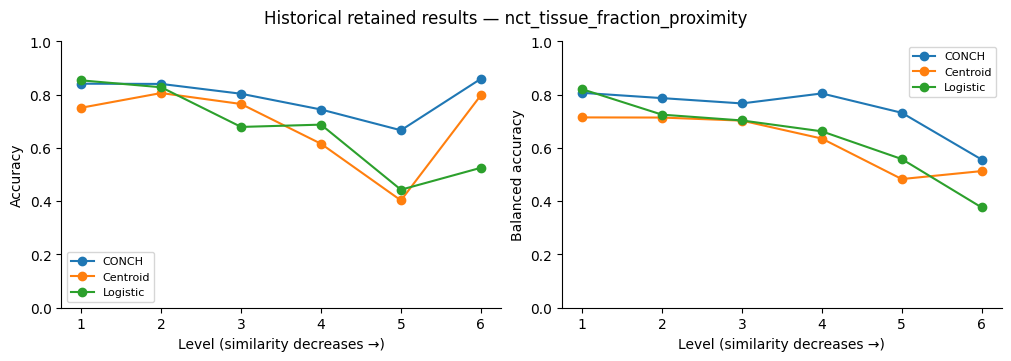

,model,level,n,axis_mean,accuracy,balanced_accuracy
0,CONCH,1,1197,-0.041226,0.841270,0.807043
1,CONCH,2,1197,-0.065186,0.840434,0.787157
2,CONCH,3,1196,-0.095089,0.803512,0.767182
3,CONCH,4,1197,-0.171527,0.744361,0.804682
4,CONCH,5,1196,-0.350056,0.666388,0.732045
5,CONCH,6,1197,-0.823209,0.859649,0.556350
6,Centroid,1,1197,-0.041226,0.751044,0.714695
7,Centroid,2,1197,-0.065186,0.806182,0.714146
8,Centroid,3,1196,-0.095089,0.765050,0.702598
9,Centroid,4,1197,-0.171527,0.615706,0.635209


Historical retained results: target and both comparator curves match the selected analysis summary to 1e-12.


In [13]:
curve=plot_axis(discovery,AXIS,LEVEL,summary['axis_summaries'][AXIS_NAME],AXIS_NAME)
display(curve[['model','level','n','axis_mean','accuracy','balanced_accuracy']])
print(DATA_MODE+': target and both comparator curves match the selected analysis summary to 1e-12.')


In [14]:
control=pd.DataFrame(analysis_source.class_adjusted_residual_by_level(discovery,LEVEL,'pred'))
stable=analysis_source.stable_class_macro(discovery,LEVEL,'pred',min_support=10)
display(control);display(pd.DataFrame(stable['rows']))


,level,n,mean_class_adjusted_correct_residual
0,1,1197,0.041112
1,2,1197,0.000195
2,3,1196,0.028136
3,4,1197,0.016357
4,5,1196,-0.106165
5,6,1197,0.020301


,level,stable_class_macro_recall,stable_classes,supports
0,1,0.778523,[TUM],{'TUM': 149}
1,2,0.652174,[TUM],{'TUM': 115}
2,3,0.629630,[TUM],{'TUM': 243}
3,4,0.574132,[TUM],{'TUM': 317}
4,5,0.390374,[TUM],{'TUM': 374}
5,6,0.114286,[TUM],{'TUM': 35}


## 6. Original follow-up panels on this same axis

The original agent selected the TUM-localized hypothesis after seeing discovery results. It streamed 600 TUM images from each of three named NONORM shards, froze six levels, and then scored 1,800 images. The later 4,000-row expansion is a separate retained panel. Its original construction, scoring and reporting scripts were recovered from the parent June 3 native session, together with original execution commands and the final determination.

In [15]:
original_functions('build_tum_confirmation_panel.py',['main'])
original_functions('score_tum_confirmation.py',['main'])

def main() -> int:
    ap = argparse.ArgumentParser()
    ap.add_argument("--nct-reference", type=Path, default=Path("spectra_ready_dataset/nct_reference_features.csv"))
    ap.add_argument("--out", type=Path, default=Path("spectra_ready_dataset/tum_confirmation_panel.csv"))
    ap.add_argument("--axis-ledger", type=Path, default=Path("axis_ledger.json"))
    ap.add_argument("--per-shard", type=int, default=600)
    ap.add_argument("--levels", type=int, default=6)
    ap.add_argument("--force-exit", action="store_true")
    args = ap.parse_args()

    ref = pd.read_csv(args.nct_reference)
    ref_tissue_median = ref[TISSUE_COLS].median()
    rows = []
    for shard_idx, shard in enumerate(NONORM_TUM_SHARDS):
        ds = load_dataset("parquet", data_files=HF_BASE + shard, split="train", streaming=True)
        taken = 0
        for local_idx, ex in enumerate(ds):
            if int(ex["label"]) != 8:
                continue
            feats = image_features(ex["image"])
            row = {
                "source_split": "NCT_CRC_HE_100K_NONORM_TUM_confirmation",
                "source_record_index": len(rows),
                "sample_id": f"nct_nonorm_tum_s{shard_idx}_{taken:04d}",
                "stream_shard": shard,
                "stream_local_seen_index": int(local_idx),
                "image_path": "",
                "label": 8,
                "label_name": LABEL_NAMES[8],
            } | feats
            rows.append(row)
            taken += 1
            if taken >= args.per_shard:
                break
        if taken < args.per_shard:
            raise RuntimeError(f"Only collected {taken} examples from {shard}")

    df = pd.DataFrame(rows)
    tissue_delta = np.sqrt(((df[TISSUE_COLS] - ref_tissue_median) ** 2).sum(axis=1))
    df["axis_nct_tissue_fraction_similarity"] = -tissue_delta.astype(float)
    levels, thresholds = assign_similarity_levels(df["axis_nct_tissue_fraction_similarity"], args.levels)
    df["level_nct_tissue_fraction_proximity"] = levels
    args.out.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(args.out, index=False)

    summary = []
    for level, part in df.groupby("level_nct_tissue_fraction_proximity", sort=True):
        summary.append(
            {
                "level": int(level),
                "n": int(len(part)),
                "axis_mean": float(part["axis_nct_tissue_fraction_similarity"].mean()),
                "axis_min": float(part["axis_nct_tissue_fraction_similarity"].min()),
                "axis_max": float(part["axis_nct_tissue_fraction_similarity"].max()),
            }
        )
    ledger = json.loads(args.axis_ledger.read_text())
    ledger.setdefault("outcome_informed_hypotheses", {})["tum_tissue_fraction_confirmation"] = {
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "status": "frozen_before_confirmation_target_scoring",
        "discovery_source": "CRC-VAL all-scored evidence showed TUM recall decreased across the predeclared NCT tissue-fraction proximity axis",
        "hypothesis": "For true colorectal adenocarcinoma epithelium ROI patches, CONCH zero-shot TUM recall decreases as prospective tissue/white/dark/saturation fraction similarity to the NCT reference decreases.",
        "confirmation_dataset": "NCT-CRC-HE-100K-NONORM streamed TUM shards from the public HF/Zenodo mirror",
        "inclusion_criteria": "label 8/TUM patches from three NONORM TUM shards; label defines the class-localized claim boundary, not the split levels",
        "axis_col": "axis_nct_tissue_fraction_similarity",
        "level_col": "level_nct_tissue_fraction_proximity",
        "level_rule": "six equal-frequency bins over the confirmation panel; level 1 is highest NCT tissue-fraction similarity and level 6 is lowest",
        "threshold_quantiles_ascending": thresholds,
        "level_summary_before_scoring": summary,
        "split_membership_uses_target_model": False,
        "split_membership_uses_prediction_errors": False,
        "

def main() -> int:
    ap = argparse.ArgumentParser()
    ap.add_argument("--conch-source", type=Path, required=True)
    ap.add_argument("--checkpoint", type=Path, required=True)
    ap.add_argument("--prompt-json", type=Path, required=True)
    ap.add_argument("--panel", type=Path, default=Path("spectra_ready_dataset/tum_confirmation_panel.csv"))
    ap.add_argument("--out", type=Path, default=Path("artifacts/tum_confirmation/target_model_results_tum_confirmation.csv"))
    ap.add_argument("--summary", type=Path, default=Path("artifacts/tum_confirmation/summary.json"))
    ap.add_argument("--batch-size", type=int, default=128)
    ap.add_argument("--force-exit", action="store_true")
    args = ap.parse_args()

    sys.path.insert(0, str(args.conch_source))
    from conch.downstream.zeroshot_path import zero_shot_classifier
    from conch.open_clip_custom import create_model_from_pretrained

    panel = pd.read_csv(args.panel)
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    print(f"device={device}", flush=True)
    model, preprocess = create_model_from_pretrained(
        "conch_ViT-B-16", checkpoint_path=str(args.checkpoint), device=device
    )
    model.eval()
    classnames, templates = load_crc_prompts(args.prompt_json)
    with torch.inference_mode():
        classifier = zero_shot_classifier(model, classnames, templates, device=device)
    logit_scale = float(model.logit_scale.exp().detach().cpu().item())

    rows = []
    batch_tensors = []
    batch_meta = []

    def flush_batch():
        nonlocal batch_tensors, batch_meta, rows
        if not batch_tensors:
            return
        imgs = torch.stack(batch_tensors, dim=0).to(device, non_blocking=True)
        with torch.inference_mode():
            image_features = model.encode_image(imgs)
            logits = image_features @ classifier
            probs = F.softmax(logits * logit_scale, dim=1)
            preds = logits.argmax(dim=1)
        logits_np = logits.detach().cpu().numpy()
        probs_np = probs.detach().cpu().numpy()
        preds_np = preds.detach().cpu().numpy()
        for meta, logit_row, prob_row, pred in zip(batch_meta, logits_np, probs_np, preds_np):
            out = {
                "sample_id": meta.sample_id,
                "label": int(meta.label),
                "label_name": meta.label_name,
                "pred": int(pred),
                "pred_label_name": LABEL_NAMES[int(pred)],
                "correct": int(int(pred) == int(meta.label)),
            }
            for i in range(len(LABEL_NAMES)):
                out[f"logit_{LABEL_NAMES[i]}"] = float(logit_row[i])
                out[f"prob_{LABEL_NAMES[i]}"] = float(prob_row[i])
            rows.append(out)
        batch_tensors = []
        batch_meta = []

    for row, image in stream_selected(panel):
        batch_tensors.append(preprocess(image))
        batch_meta.append(row)
        if len(batch_tensors) >= args.batch_size:
            flush_batch()
            if len(rows) % (args.batch_size * 5) == 0:
                print(f"scored={len(rows)}", flush=True)
    flush_batch()
    df = pd.DataFrame(rows)
    if len(df) != len(panel):
        raise RuntimeError(f"Scored {len(df)} rows for panel of {len(panel)}")
    args.out.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(args.out, index=False)
    summary = {
        "n": int(len(df)),
        "accuracy_tum_recall": float(accuracy_score(df["label"], df["pred"])),
        "prediction_counts": {LABEL_NAMES[int(k)]: int(v) for k, v in df["pred"].value_counts().sort_index().items()},
    }
    args.summary.write_text(json.dumps(summary, indent=2))
    print(json.dumps(summary, indent=2), flush=True)
    if args.force_exit:
        os._exit(0)
    return 0

In [16]:
original_functions('build_tum_expansion_panel.py',['main'])
original_functions('score_tum_panel_generic.py',['main'])
for record in json.loads((ROOT/'originals/expansion_executed_commands.json').read_text()):
    print(f"Parent session line {record['native_session_line']} — {record['timestamp']}")
    print(record['command'])

def main() -> int:
    ap = argparse.ArgumentParser()
    ap.add_argument("--nct-reference", type=Path, default=Path("spectra_ready_dataset/nct_reference_features.csv"))
    ap.add_argument("--previous-panel", type=Path, default=Path("spectra_ready_dataset/tum_confirmation_panel.csv"))
    ap.add_argument("--out", type=Path, default=Path("spectra_ready_dataset/tum_expansion_panel.csv"))
    ap.add_argument("--diagnostics", type=Path, default=Path("artifacts/tum_expansion/panel_diagnostics.json"))
    ap.add_argument("--axis-ledger", type=Path, default=Path("axis_ledger.json"))
    ap.add_argument("--per-shard", type=int, default=1000)
    ap.add_argument("--levels", type=int, default=10)
    args = ap.parse_args()

    ref = pd.read_csv(args.nct_reference)
    previous = pd.read_csv(args.previous_panel)
    ref_tissue_median = ref[TISSUE_COLS].median()
    used_stream_keys = {
        (row.stream_shard, int(row.stream_local_seen_index))
        for row in previous.itertuples(index=False)
    }
    previous_md5 = set(previous["image_md5"].dropna().astype(str))
    previous_dhash = set(previous["dhash64"].dropna().astype(str))

    rows = []
    internal_md5 = set()
    skipped = {"previous_stream_key": 0, "previous_md5": 0, "internal_md5": 0}
    dhash_overlap_with_previous = 0

    for shard_idx, shard in enumerate(NONORM_TUM_EXPANSION_SHARDS):
        ds = load_dataset("parquet", data_files=HF_BASE + shard, split="train", streaming=True)
        taken = 0
        seen = 0
        for local_idx, ex in enumerate(ds):
            seen += 1
            if int(ex["label"]) != 8:
                continue
            stream_key = (shard, int(local_idx))
            if stream_key in used_stream_keys:
                skipped["previous_stream_key"] += 1
                continue
            feats = image_features(ex["image"])
            image_md5 = str(feats["image_md5"])
            if image_md5 in previous_md5:
                skipped["previous_md5"] += 1
                continue
            if image_md5 in internal_md5:
                skipped["internal_md5"] += 1
                continue
            internal_md5.add(image_md5)
            if str(feats["dhash64"]) in previous_dhash:
                dhash_overlap_with_previous += 1
            rows.append(
                {
                    "source_split": "NCT_CRC_HE_100K_NONORM_TUM_expansion",
                    "source_record_index": len(rows),
                    "sample_id": f"nct_nonorm_tum_exp_s{shard_idx}_{taken:04d}",
                    "stream_shard": shard,
                    "stream_local_seen_index": int(local_idx),
                    "image_path": "",
                    "label": 8,
                    "label_name": LABEL_NAMES[8],
                }
                | feats
            )
            taken += 1
            if taken >= args.per_shard:
                break
        if taken < args.per_shard:
            raise RuntimeError(f"Only collected {taken} unused TUM examples from {shard} after seeing {seen}")

    df = pd.DataFrame(rows)
    tissue_delta = np.sqrt(((df[TISSUE_COLS] - ref_tissue_median) ** 2).sum(axis=1))
    df["axis_nct_tissue_fraction_similarity"] = -tissue_delta.astype(float)
    levels, thresholds = assign_similarity_levels(df["axis_nct_tissue_fraction_similarity"], args.levels)
    df["level_nct_tissue_fraction_proximity"] = levels
    args.out.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(args.out, index=False)

    level_summary = []
    feature_cols = TISSUE_COLS + ["gray_mean", "gray_std", "gray_entropy", "edge_mean"]
    for level, part in df.groupby("level_nct_tissue_fraction_proximity", sort=True):
        level_summary.append(
            {
                "level": int(level),
                "n": int(len(part)),
                "axis_mean": float(part["axis_nct_tissue_fraction_similarity"].mean()),
                "axis_min": float(part["axis_nct_tissue_fraction_similarity"].min()),
                "axis_max": float(pa

def main() -> int:
    ap = argparse.ArgumentParser()
    ap.add_argument("--conch-source", type=Path, required=True)
    ap.add_argument("--checkpoint", type=Path, required=True)
    ap.add_argument("--prompt-json", type=Path, required=True)
    ap.add_argument("--panel", type=Path, required=True)
    ap.add_argument("--out", type=Path, required=True)
    ap.add_argument("--summary", type=Path, required=True)
    ap.add_argument("--batch-size", type=int, default=128)
    args = ap.parse_args()

    sys.path.insert(0, str(args.conch_source))
    from conch.downstream.zeroshot_path import zero_shot_classifier
    from conch.open_clip_custom import create_model_from_pretrained

    panel = pd.read_csv(args.panel)
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    print(f"device={device}", flush=True)
    model, preprocess = create_model_from_pretrained(
        "conch_ViT-B-16", checkpoint_path=str(args.checkpoint), device=device
    )
    model.eval()
    classnames, templates = load_crc_prompts(args.prompt_json)
    with torch.inference_mode():
        classifier = zero_shot_classifier(model, classnames, templates, device=device)
    logit_scale = float(model.logit_scale.exp().detach().cpu().item())

    rows = []
    batch_tensors = []
    batch_meta = []

    def flush_batch():
        nonlocal batch_tensors, batch_meta, rows
        if not batch_tensors:
            return
        imgs = torch.stack(batch_tensors, dim=0).to(device, non_blocking=True)
        with torch.inference_mode():
            image_features = model.encode_image(imgs)
            logits = image_features @ classifier
            probs = F.softmax(logits * logit_scale, dim=1)
            preds = logits.argmax(dim=1)
        logits_np = logits.detach().cpu().numpy()
        probs_np = probs.detach().cpu().numpy()
        preds_np = preds.detach().cpu().numpy()
        for meta, logit_row, prob_row, pred in zip(batch_meta, logits_np, probs_np, preds_np):
            out = {
                "sample_id": meta.sample_id,
                "label": int(meta.label),
                "label_name": meta.label_name,
                "pred": int(pred),
                "pred_label_name": LABEL_NAMES[int(pred)],
                "correct": int(int(pred) == int(meta.label)),
            }
            for i in range(len(LABEL_NAMES)):
                out[f"logit_{LABEL_NAMES[i]}"] = float(logit_row[i])
                out[f"prob_{LABEL_NAMES[i]}"] = float(prob_row[i])
            rows.append(out)
        batch_tensors = []
        batch_meta = []

    for row, image in stream_selected(panel):
        batch_tensors.append(preprocess(image))
        batch_meta.append(row)
        if len(batch_tensors) >= args.batch_size:
            flush_batch()
            print(f"scored={len(rows)}/{len(panel)}", flush=True)
    flush_batch()

    df = pd.DataFrame(rows)
    if len(df) != len(panel):
        raise RuntimeError(f"Scored {len(df)} rows for panel of {len(panel)}")
    args.out.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(args.out, index=False)
    summary = {
        "n": int(len(df)),
        "accuracy_tum_recall": float(accuracy_score(df["label"], df["pred"])),
        "prediction_counts": {LABEL_NAMES[int(k)]: int(v) for k, v in df["pred"].value_counts().sort_index().items()},
    }
    args.summary.write_text(json.dumps(summary, indent=2))
    print(json.dumps(summary, indent=2), flush=True)
    return 0

Parent session line 1624 — 2026-06-03T14:35:08.109Z
HF_HOME=/path/to/original-audit-home/.cache/spectra/hf HF_DATASETS_CACHE=/path/to/original-audit-home/.cache/spectra/hf/datasets /path/to/original-workspace/envs/envs/pgt/bin/python scripts/build_tum_expansion_panel.py --per-shard 1000 --levels 10
Parent session line 1643 — 2026-06-03T14:36:10.043Z
CUDA_VISIBLE_DEVICES=7 HF_HOME=/path/to/original-audit-home/.cache/spectra/hf HF_DATASETS_CACHE=/path/to/original-audit-home/.cache/spectra/hf/datasets /path/to/original-workspace/envs/envs/pgt/bin/python scripts/score_tum_panel_generic.py --conch-source /path/to/original-audit-home/.cache/spectra/runs/conch_generalizability_audit_20260603/source/CONCH --checkpoint model_cache/models--MahmoodLab--conch/snapshots/f9ca9f877171a28ade80228fb195ac5d79003357/pytorch_model.bin --prompt-json /path/to/original-audit-home/.cache/spectra/runs/conch_generalizability_audit_20260603/source/CONCH/prompts/crc100k_prompts_all_per_class.json --panel spectra_

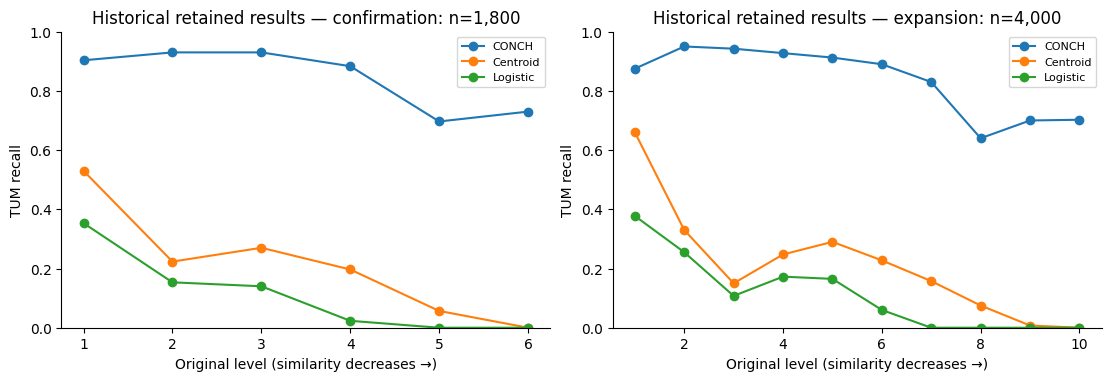

,panel,model,level,n,recall
0,confirmation,CONCH,1,300,0.903333
1,confirmation,CONCH,2,300,0.930000
2,confirmation,CONCH,3,300,0.930000
3,confirmation,CONCH,4,300,0.883333
4,confirmation,CONCH,5,300,0.696667
5,confirmation,CONCH,6,300,0.730000
6,confirmation,Centroid,1,300,0.530000
7,confirmation,Centroid,2,300,0.223333
8,confirmation,Centroid,3,300,0.270000
9,confirmation,Centroid,4,300,0.196667


Historical retained results: confirmation/expansion distances, assignments and model recalls verified.


In [17]:
panel_rows=[]
fig,axs=plt.subplots(1,2,figsize=(11,3.7),layout='constrained')
for ax,phase,n in zip(axs,['confirmation','expansion'],[1800,4000]):
    panel=pd.read_csv(RESULT_PATHS[phase]);assert len(panel)==n
    for prefix in ['logit_','prob_']:
        np.testing.assert_array_equal(panel[[prefix+c for c in classes]].to_numpy().argmax(1),panel.pred)
    assert panel.sample_id.is_unique and panel.image_md5.is_unique
    assert not panel[['stream_shard','stream_local_seen_index']].duplicated().any()
    expected=json.loads((RUN/f'artifacts/tum_{phase}/analysis.json').read_text())
    # Same input-feature formula, distinct original panel and number of levels.
    x=panel[reference['columns']].to_numpy()
    rebuilt=-np.sqrt(((x-np.array(reference['median']))**2).sum(axis=1))
    np.testing.assert_allclose(rebuilt,panel[AXIS],atol=1e-10,rtol=0)
    assigned,_=axis_source.assign_similarity_levels(panel[AXIS],panel[LEVEL].nunique())
    np.testing.assert_array_equal(assigned,panel[LEVEL])
    for model,col,stored in [('CONCH','pred','target_by_level'),('Centroid','baseline_centroid_pred','baseline_centroid_by_level'),('Logistic','baseline_logistic_pred','baseline_logistic_by_level')]:
        calc=panel.assign(correct=(panel[col]==panel.label)).groupby(LEVEL).agg(n=('correct','size'),recall=('correct','mean'))
        np.testing.assert_allclose(calc.recall,[r['tum_recall'] for r in expected[stored]],atol=1e-12,rtol=0)
        ax.plot(calc.index,calc.recall,marker='o',label=model)
        panel_rows.extend({'panel':phase,'model':model,'level':int(level),'n':int(row.n),'recall':row.recall} for level,row in calc.iterrows())
    ax.set(title=f'{DATA_MODE} — {phase}: n={n:,}',xlabel='Original level (similarity decreases →)',ylabel='TUM recall',ylim=(0,1))
    ax.legend(fontsize=8);ax.spines[['top','right']].set_visible(False)
plt.show();display(pd.DataFrame(panel_rows))
print(DATA_MODE+': confirmation/expansion distances, assignments and model recalls verified.')


## 7. Original expansion uncertainty and final determination

These are the original Wilson intervals and pooled high-versus-tail contrast from the recovered report script. They reproduce the historical analysis; the selected contrast and the original public-source-family limit are preserved.

In [18]:
import report_tum_expansion as expansion_report
expansion=pd.read_csv(RESULT_PATHS['expansion'])
rows=[]
for level,g in expansion.groupby(LEVEL):
    k=int((g.pred==g.label).sum());n=len(g)
    rows.append({'level':int(level),'n':n,'tum_recall':k/n,
                 'ci95':expansion_report.wilson(k,n)})
high=expansion_report.pooled(rows,set(range(1,8)))
tail=expansion_report.pooled(rows,{8,9,10})
contrast=expansion_report.diff_test(high,tail)
if not RUN_ORIGINAL_WORKFLOW:
    assert (high['k'],high['n'],tail['k'],tail['n'])==(2531,2800,817,1200)
    np.testing.assert_allclose(contrast['difference'],0.22309523809523812,atol=1e-12)
    assert [f'{x:.3f}' for x in contrast['ci95']]==['0.195','0.252']
print(DATA_MODE+': original contrast definition evaluated on the selected predictions.')
display(pd.DataFrame(rows));display(pd.DataFrame([high,tail]));display(contrast)
original_functions('report_tum_expansion.py',['wilson','pooled','diff_test'])
display(Markdown('**Historical report and agent interpretation (not a new rerun determination)**'))
display(Markdown((ORIGINAL_RUN/'artifacts/tum_expansion/expanded_finding_report.md').read_text()))
for message in json.loads((ROOT/'originals/expansion_agent_determinations.json').read_text()):
    if message['native_session_line']==1834:
        display(Markdown('**Original parent-session final determination, line 1834**\n\n'+message['text']))


Historical retained results: original contrast definition evaluated on the selected predictions.


,level,n,tum_recall,ci95
0,1,400,0.8750,"(0.8389801748486139, 0.9038853447016257)"
1,2,400,0.9500,"(0.9240357990869275, 0.9674028243733599)"
2,3,400,0.9425,"(0.9151985747985072, 0.9613827382707756)"
3,4,400,0.9275,"(0.8978168807373348, 0.9490498115499382)"
4,5,400,0.9125,"(0.88073860783094, 0.9364134636743233)"
5,6,400,0.8900,"(0.8555483868341889, 0.9170317534980603)"
6,7,400,0.8300,"(0.7900900795523471, 0.8636315776518637)"
7,8,400,0.6400,"(0.5918335636186343, 0.6855028970134551)"
8,9,400,0.7000,"(0.6533618692890616, 0.7428330744710662)"
9,10,400,0.7025,"(0.6559441809772917, 0.7452031995798376)"


,levels,n,k,recall,ci95
0,"[1, 2, 3, 4, 5, 6, 7]",2800,2531,0.903929,"[0.8924531507583335, 0.9142971307126311]"
1,"[8, 9, 10]",1200,817,0.680833,"[0.6539169370124235, 0.7065956088241715]"


{'difference': 0.22309523809523812,
 'ci95': [0.19455063553739568, 0.25163984065308054],
 'z': 17.50545536021469,
 'p_two_sided_normal': 1.301817873266392e-68}

def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    denom = 1.0 + z * z / n
    center = (p + z * z / (2 * n)) / denom
    half = z * math.sqrt((p * (1 - p) + z * z / (4 * n)) / n) / denom
    return center - half, center + half

def pooled(rows: list[dict], levels: set[int]) -> dict:
    chosen = [r for r in rows if int(r["level"]) in levels]
    n = sum(int(r["n"]) for r in chosen)
    k = sum(round(float(r["tum_recall"]) * int(r["n"])) for r in chosen)
    lo, hi = wilson(k, n)
    return {"levels": sorted(levels), "n": n, "k": k, "recall": k / n, "ci95": [lo, hi]}

def diff_test(a: dict, b: dict) -> dict:
    p1 = a["k"] / a["n"]
    p2 = b["k"] / b["n"]
    diff = p1 - p2
    se = math.sqrt(p1 * (1 - p1) / a["n"] + p2 * (1 - p2) / b["n"])
    ci = [diff - 1.96 * se, diff + 1.96 * se]
    pooled_p = (a["k"] + b["k"]) / (a["n"] + b["n"])
    pooled_se = math.sqrt(pooled_p * (1 - pooled_p) * (1 / a["n"] + 1 / b["n"]))
    z = diff / pooled_se if pooled_se else float("inf")
    p = math.erfc(abs(z) / math.sqrt(2))
    return {"difference": diff, "ci95": ci, "z": z, "p_two_sided_normal": p}

**Historical report and agent interpretation (not a new rerun determination)**

# CONCH TUM Tissue/Stain-Fraction SPC Expansion

## Status

This expansion strengthens the prior localized finding. The same prospective axis was kept frozen before target scoring: Euclidean distance in tissue, white, dark, and high-saturation pixel fractions from the class-balanced NCT reference median, with higher numbered levels meaning lower similarity.

The expanded panel used 4,000 unused NCT-CRC-HE-100K-NONORM TUM images, 400 per frozen level. It excluded all 1,800 previously scored confirmation rows by stream key and exact decoded-image MD5. Internal exact MD5 duplicates were 0, exact overlap with the previous panel was 0, and dHash64 overlap with the previous panel was 0. Mean measured similarity decreased across all 10 levels.

Validity decision: `valid` for the bounded public CRC ROI TUM low-similarity tail boundary; `weak` for independent-site or deployment generalization because all confirmation evidence is still from the public Kather/NCT source family.

## Expanded Curve

| Level | n | Axis Mean | CONCH TUM Recall | 95% CI | Centroid | Logistic | Dark Mean | Sat-High Mean |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1 | 400 | -0.032 | 0.875 | [0.839, 0.904] | 0.660 | 0.378 | 0.004 | 0.063 |
| 2 | 400 | -0.052 | 0.950 | [0.924, 0.967] | 0.330 | 0.255 | 0.003 | 0.043 |
| 3 | 400 | -0.065 | 0.943 | [0.915, 0.961] | 0.150 | 0.107 | 0.002 | 0.027 |
| 4 | 400 | -0.079 | 0.927 | [0.898, 0.949] | 0.247 | 0.172 | 0.003 | 0.047 |
| 5 | 400 | -0.107 | 0.912 | [0.881, 0.936] | 0.290 | 0.165 | 0.006 | 0.065 |
| 6 | 400 | -0.153 | 0.890 | [0.856, 0.917] | 0.228 | 0.060 | 0.010 | 0.069 |
| 7 | 400 | -0.245 | 0.830 | [0.790, 0.864] | 0.158 | 0.000 | 0.021 | 0.099 |
| 8 | 400 | -0.434 | 0.640 | [0.592, 0.686] | 0.075 | 0.000 | 0.104 | 0.320 |
| 9 | 400 | -0.640 | 0.700 | [0.653, 0.743] | 0.007 | 0.000 | 0.245 | 0.591 |
| 10 | 400 | -0.847 | 0.703 | [0.656, 0.745] | 0.000 | 0.000 | 0.388 | 0.799 |

## Main Contrast

Levels 1-7 stayed high overall: 2531/2800 = 0.904 TUM recall, 95% CI [0.892, 0.914].

Levels 8-10 formed the low-similarity tail: 817/1200 = 0.681 TUM recall, 95% CI [0.654, 0.707].

Difference, levels 1-7 minus 8-10: 0.223, 95% CI [0.195, 0.252], two-sided normal p ~= 1.30e-68.

The curve is threshold-shaped rather than strictly monotone: levels 8-10 are consistently degraded, but level 9 and 10 rebound slightly relative to level 8. Spearman level-vs-recall over the 10 frozen bins is -0.770.

## Baseline Comparison

CONCH overall TUM recall on the expansion panel was 0.837. Fixed feature baselines were much lower: centroid 0.214, logistic 0.114. The baselines also degrade strongly in the low-similarity tail, which supports the axis as a real prospective image-distribution shift rather than a CONCH-confidence artifact.

## Interpretation

The low-similarity tail is not simply low tissue area. In the expanded panel it is mainly a dark/high-saturation stain tail: mean dark fraction rises from 0.004 at level 1 to 0.388 at level 10, and high-saturation fraction rises from 0.063 to 0.799.

Exploratory failure characterization, not an axis definition: in levels 8-10, non-TUM predictions were mostly STR, MUC, DEB, and BACK. This was computed after target scoring and should not be used as confirmatory split logic.

## Relation To Previous Confirmation

The earlier six-level confirmation had TUM recall [0.903, 0.930, 0.930, 0.883, 0.697, 0.730]. The expanded 10-level panel reproduces the same low-tail shape with more examples per level: levels 8-10 were [0.640, 0.700, 0.703].

## Artifacts

- `spectra_ready_dataset/tum_expansion_panel.csv`
- `artifacts/tum_expansion/panel_diagnostics.json`
- `artifacts/tum_expansion/target_model_results_tum_expansion.csv`
- `artifacts/tum_expansion/analysis.json`
- `artifacts/tum_expansion/expanded_metrics.json`
- `artifacts/tum_expansion/scored_tum_expansion_with_baselines.csv`


**Original parent-session final determination, line 1834**

Expanded the finding and finished the run. No scoring processes are still running.

The expanded SPECTRA result is stronger: using the same frozen prospective TUM tissue/stain-fraction axis, I added `4,000` unused NONORM TUM images, split into `10` frozen similarity levels with `400` images each. The panel excluded all prior `1,800` confirmation rows, had `0` exact MD5 duplicates, `0` exact overlap, `0` dHash overlap, and measured similarity decreased across all 10 levels before CONCH scoring.

CONCH TUM recall by level:

`[0.875, 0.950, 0.943, 0.927, 0.912, 0.890, 0.830, 0.640, 0.700, 0.703]`

Main readout:
- Levels `1-7`: `2531/2800 = 0.904` recall, 95% CI `[0.892, 0.914]`
- Levels `8-10`: `817/1200 = 0.681` recall, 95% CI `[0.654, 0.707]`
- Difference: `0.223`, 95% CI `[0.195, 0.252]`
- Spearman level-vs-recall: `-0.770`

So the finding is now best described as a **threshold-shaped low-similarity tail degradation**, not a smooth monotone decline. The low-similarity tail is mainly a **dark/high-saturation stain tail**, not simply low tissue area.

Validity update: **valid for the bounded public CRC ROI TUM low-similarity tail boundary**, but still **weak for independent-site/deployment generalization** because the expanded confirmation is still within the public Kather/NCT source family.

Artifacts:
- [expanded_finding_report.md](/path/to/original-audit-home/.cache/spectra/runs/conch_generalizability_audit_20260603_unblocked/artifacts/tum_expansion/expanded_finding_report.md)
- [expanded_metrics.json](/path/to/original-audit-home/.cache/spectra/runs/conch_generalizability_audit_20260603_unblocked/artifacts/tum_expansion/expanded_metrics.json)
- [tum_expansion_panel.csv](/path/to/original-audit-home/.cache/spectra/runs/conch_generalizability_audit_20260603_unblocked/spectra_ready_dataset/tum_expansion_panel.csv)
- [target_model_results_tum_expansion.csv](/path/to/original-audit-home/.cache/spectra/runs/conch_generalizability_audit_20260603_unblocked/artifacts/tum_expansion/target_model_results_tum_expansion.csv)
- [axis_ledger.json](/path/to/original-audit-home/.cache/spectra/runs/conch_generalizability_audit_20260603_unblocked/axis_ledger.json)

## Original agent determination and remaining source boundary

The original agent retained a localized TUM tissue-fraction finding after the original 1,800-image NONORM confirmation, then the separately archived 4,000-image expansion. The original language and both panels remain separate below.

In [19]:
messages=json.loads((ROOT/'originals/agent_determinations.json').read_text())
for row in messages:
    if row['native_session_line'] in [411,627,632,707,713,719,725,745]:
        display(Markdown(f"**Original session line {row['native_session_line']} ({row['timestamp']})**\n\n"+row['text']))
display(Markdown('**Original historical final report; regenerated curves above are separate.**'))
display(Markdown((ORIGINAL_RUN/'final_report.md').read_text()))
status=json.loads((ROOT/'recovery_status.json').read_text())
print('Original-source items still not located (not new scientific acceptance criteria):')
for item in status['unresolved_originals']: print('-',item)
print('Portable offline replay: raw-image checks are optional; the generated workflow uses acquired pixels and never substitutes archived target scores.')


**Original session line 411 (2026-06-03T13:00:07.850Z)**

The primary frozen axis is valid in ordering, but its raw levels have noticeable label-composition shifts. That does not invalidate scoring, but the closure check will need class-adjusted evidence and fixed baselines before making any claim.

**Original session line 627 (2026-06-03T13:23:15.596Z)**

The broad all-axis pass found a stronger, interpretable localized hypothesis than the primary raw curve: true TUM recall falls sharply as the predeclared tissue-fraction proximity axis decreases. Because that class-localized finding was selected after seeing results, I’m treating it as a live hypothesis and will freeze a fresh confirmation panel before scoring it.

**Original session line 632 (2026-06-03T13:23:20.784Z)**

For confirmation I’ll use fresh public NCT-CRC-HE-100K-NONORM TUM patches from the HF/Zenodo mirror, streamed shard-first rather than downloading the 11.7 GB archive. Claim boundary will explicitly include the limitation that this confirmation is public CRC ROI data and not an independent hospital/site cohort.

**Original session line 707 (2026-06-03T13:30:51.086Z)**

The fresh confirmation supports a threshold-style boundary: TUM recall is about 0.90-0.93 in levels 1-4 and drops to about 0.70-0.73 in levels 5-6. I’m densifying the same frozen confirmation axis to deciles using the already-scored panel to check whether that threshold shape is stable.

**Original session line 713 (2026-06-03T13:31:02.234Z)**

Decile densification keeps the same threshold interpretation: levels 1-7 are mostly 0.85-0.94 TUM recall, while levels 8-10 sit around 0.68-0.73. I’m checking the analogous CRC-VAL TUM-only curve so the discovery and confirmation evidence are summarized on the same axis.

**Original session line 719 (2026-06-03T13:31:12.692Z)**

The CRC-VAL TUM-only discovery curve is stronger and more graded, while NONORM confirmation is a milder threshold drop. I’m summarizing what the low-similarity levels mean in concrete image-feature terms so the claim boundary is interpretable.

**Original session line 725 (2026-06-03T13:31:38.349Z)**

The closure gate is now satisfiable for a localized claim: the axis was frozen before confirmation scoring, has ordered levels, 300 confirmation examples per level, a densified decile check, fixed baselines, and a clear claim boundary. I’m writing the compact state, ledger updates, command log, and final report now.

**Original session line 745 (2026-06-03T13:33:03.618Z)**

Terminal gate passed. I wrote `final_report.md` because the run now has a claim-valid localized SPC, not just a weak checkpoint.

Claim boundary: CONCH zero-shot CRC ROI classification generalizes well overall on CRC-VAL, but TUM / colorectal adenocarcinoma epithelium recall shows a threshold degradation for patches with low prospective tissue-fraction similarity to the NCT reference. This is not a broad hospital/site, WSI, non-CRC, or all-class claim.

Key evidence:
- CRC-VAL full run: 7,180 images, CONCH accuracy `0.793`, balanced accuracy `0.785`.
- CRC-VAL TUM discovery curve across decreasing tissue-fraction similarity: recall `[0.779, 0.652, 0.630, 0.574, 0.390, 0.114]`.
- Fresh NONORM TUM confirmation: 1,800 images, 300 per frozen level, recall `[0.903, 0.930, 0.930, 0.883, 0.697, 0.730]`.
- Decile densification preserved the low-similarity threshold: deciles 8-10 were `[0.678, 0.733, 0.722]`.
- Fixed feature baselines were run and were weaker.

No hard blocker remains. Main limitation: confirmation is fresh relative to CRC-VAL discovery, but still from the public Kather/NCT source family, not an independent hospital cohort.

Artifacts:
- [final_report.md](/path/to/original-audit-home/.cache/spectra/runs/conch_generalizability_audit_20260603_unblocked/final_report.md)
- [spectra_loop_state.json](/path/to/original-audit-home/.cache/spectra/runs/conch_generalizability_audit_20260603_unblocked/spectra_loop_state.json)
- [axis_ledger.json](/path/to/original-audit-home/.cache/spectra/runs/conch_generalizability_audit_20260603_unblocked/axis_ledger.json)
- [commands_run.json](/path/to/original-audit-home/.cache/spectra/runs/conch_generalizability_audit_20260603_unblocked/commands_run.json)
- [target_model_results.csv](/path/to/original-audit-home/.cache/spectra/runs/conch_generalizability_audit_20260603_unblocked/target_model_results.csv)
- [spectra_ready_dataset/](/path/to/original-audit-home/.cache/spectra/runs/conch_generalizability_audit_20260603_unblocked/spectra_ready_dataset)
- [artifacts/tum_confirmation/analysis.json](/path/to/original-audit-home/.cache/spectra/runs/conch_generalizability_audit_20260603_unblocked/artifacts/tum_confirmation/analysis.json)

**Original historical final report; regenerated curves above are separate.**

# CONCH SPECTRA Generalizability Audit

## Finding

A claim-valid but localized SPECTRA finding is supported for CONCH zero-shot CRC ROI classification: true TUM / colorectal adenocarcinoma epithelium recall degrades in the low-similarity tail of a prospective tissue-fraction axis. The axis is not target confidence or error based; it is computed from tissue, white, dark, and high-saturation pixel fractions relative to a class-balanced NCT-CRC-HE-100K reference.

Claim boundary: public CRC 224x224 H&E ROI tiles scored with the CONCH CRC prompt ensemble. This is a TUM-class, acquisition/content-quality boundary, not a broad all-class, WSI, hospital/site, non-CRC, or medical deployment claim. Confirmation is fresh relative to CRC-VAL discovery but comes from the same public Kather/NCT source family, not an independent site cohort.

## Data And Leakage Controls

- Model: `conch_ViT-B-16` from `MahmoodLab/conch`, source commit `141cc09c7d4ff33d8eda562bd75169b457f71a62`; checkpoint cached under `model_cache/` with size 802,235,437 bytes.
- Discovery/evaluation pool: all 7,180 CRC-VAL-HE-7K images from the public NCT-CRC-HE mirror. Exact MD5 duplicates: 0; dHash64 duplicates: 0.
- Prospective reference: 1,800 streamed NCT-CRC-HE-100K images, 200 per class, used only for fixed feature axes and baselines.
- Confirmation pool: 1,800 fresh NCT-CRC-HE-100K-NONORM TUM images, 600 from each of three public TUM shards, frozen into six equal-count levels before CONCH scoring.

## Key Numbers

Overall CONCH on CRC-VAL: accuracy 0.793, balanced accuracy 0.785, macro F1 0.769. Fixed NCT-feature baselines were lower: centroid balanced accuracy 0.602, logistic balanced accuracy 0.619.

CRC-VAL TUM discovery on the frozen tissue-fraction axis, levels 1 to 6 as similarity decreases: TUM recall [0.779, 0.652, 0.63, 0.574, 0.39, 0.114]. The lowest-similarity CRC-VAL TUM level had much more white/background-like area: mean tissue fraction 0.605 and white fraction 0.395, versus 0.969 tissue and 0.030 white in level 1.

NONORM TUM confirmation, 300 images per level: CONCH TUM recall [0.903, 0.93, 0.93, 0.883, 0.697, 0.73]. Densified deciles preserved the threshold shape: deciles 1-7 were mostly 0.85-0.94 recall, while deciles 8-10 were [0.678, 0.733, 0.722].

Fixed baselines on the same confirmation levels were substantially weaker and also degraded with low similarity. Centroid TUM recall by level: [0.53, 0.223, 0.27, 0.197, 0.057, 0.0]; logistic TUM recall by level: [0.353, 0.153, 0.14, 0.023, 0.0, 0.0].

## Nonprimary Axes

The broader NCT color/texture proximity axis was split-valid but not claim-closing. Its balanced accuracy fell in the low-similarity tail, but raw accuracy rose because low-similarity levels were dominated by easy ADI/BACK/DEB patches. Class-adjusted and stable-class checks did not support using it as the primary all-class generalizability claim.

## Artifacts

- `spectra_loop_state.json`
- `axis_ledger.json`
- `commands_run.json`
- `spectra_ready_dataset/`
- `target_model_results.csv`
- `artifacts/spc_analysis/spc_summary.json`
- `artifacts/tum_confirmation/analysis.json`
- `final_report.md`


Original-source items still not located (not new scientific acceptance criteria):
- Original saved NCT1800 CSV was not found; exact pinned-image reconstruction now supplies its role.
- Original target-image and checkpoint caches were not copied; the executable workflow reacquires pinned public shards and the access-controlled checkpoint.
Portable offline replay: raw-image checks are optional; the generated workflow uses acquired pixels and never substitutes archived target scores.
